# Experiment 9: training episode size — training

Compare 2,048, 8,192 and 26,000 total training rows on one fixed large-table pool. The 8,192-row control is reused explicitly from experiment 8. Context and query size both increase; update budgets, not compute or row exposures, are matched.

Does a longer training episode improve credit transfer within the same large-table corpus? Both context and query rows increase; updates are matched, compute is not.


## 0. Evidence and scope

In [1]:
%matplotlib inline
import sys
from pathlib import Path
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').is_file())
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
from src.visualize import style, campaign as cp, size_studies as ss
from src.visualize.figures import FigureSaver
from src.visualize.inputs import source_description
style.apply()
sink = FigureSaver('experiment9/01_training')
report = cp.NotebookReport('Experiment 9: training episode size — training', sink=sink)
print(source_description())
arms = ss.load_arms(7)
report.add('0. Evidence and scope', source_description() + '\n' + 'Compare 2,048, 8,192 and 26,000 total training rows on one fixed large-table pool. The 8,192-row control is reused explicitly from experiment 8. Context and query size both increase; update budgets, not compute or row exposures, are matched.')

DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


## 1. Coverage and the fixed evaluation population

In [2]:
report.table('Planned and recorded evidence', ss.coverage(arms))
report.table('Prepared corpus and exposure inventory', ss.corpus_inventory(arms))
report.add('1. Coverage and the fixed evaluation population', 'Missing records are unavailable evidence. PENDING is not a live scheduler state. The four original dataset partitions and five row-level evaluation folds remain fixed. Shared controls count once.')

,arm,source_experiment,source_run,planned,completed,other_outcomes,pending,trajectory_records,benchmark_fold_records
0,"2,048 rows",experiment7,cpt_episode_rows2048_v1,8,8,0,0,48,1155
1,"8,192 rows",experiment6,cpt_corpus_v1,8,8,0,0,48,1155
2,"26,000 rows",experiment7,cpt_episode_rows26000_v1,8,8,0,0,48,1155


,arm,partition,id,available_rows,episode_rows,query_rows,visit_share,held_out_tables
0,"2,048 rows",0,0001.gmsc,150000,2048,819,0.111111,4
1,"2,048 rows",0,0002.taiwan_creditcard,30000,2048,819,0.111111,4
2,"2,048 rows",0,0003.vehicle_loan,233154,2048,819,0.111111,4
3,"2,048 rows",0,0006.hackerearth,532428,2048,819,0.111111,4
4,"2,048 rows",0,0007.cobranded,80000,2048,819,0.111111,4
...,...,...,...,...,...,...,...,...
94,"26,000 rows",3,PropPD1,100000,26000,10400,0.111111,4
95,"26,000 rows",3,PropPD2,105471,26000,10400,0.111111,4
96,"26,000 rows",3,0014.algorithmwatch,158700,26000,10400,0.111111,4
97,"26,000 rows",3,0015.credit_risk_dataset,32581,26000,10400,0.111111,4


## 2. Optimization and parameter movement

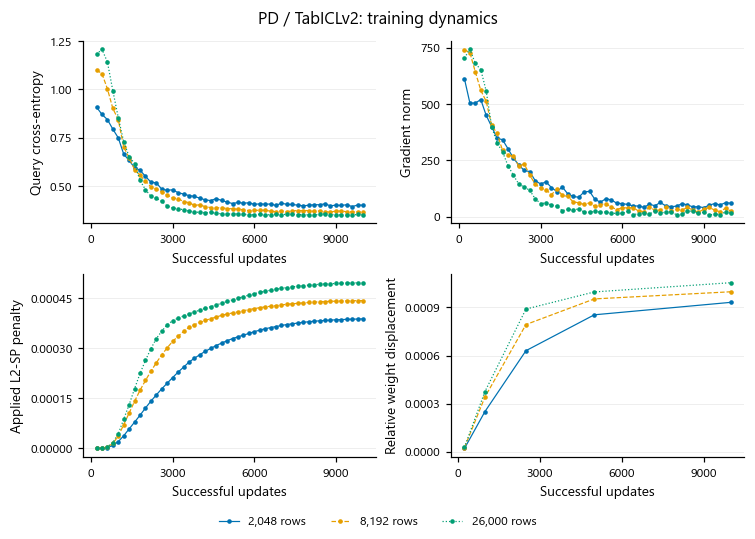

Native query cross-entropy excludes anchoring. Each line averages the four planned dataset partitions; missing partitions leave gaps. All arms use the same large-table pool. Larger episodes change both context and query counts; training loss is not a held-out transfer score. Other panels show optimization and movement, not final predictive quality.

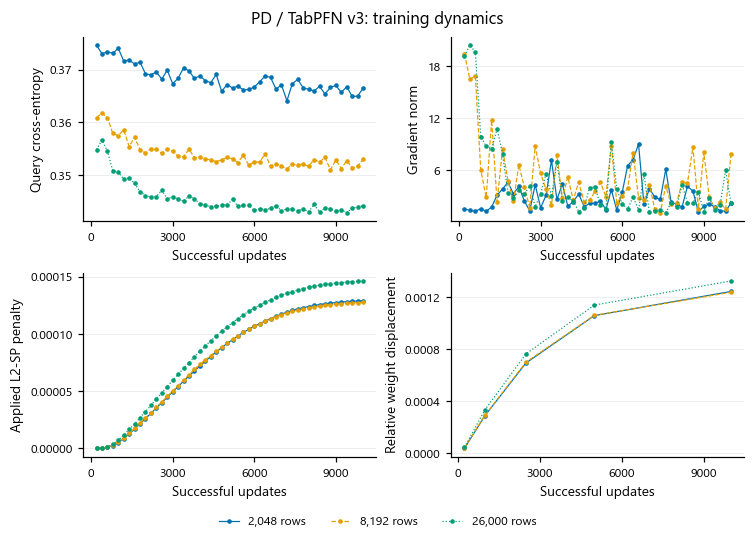

Native query cross-entropy excludes anchoring. Each line averages the four planned dataset partitions; missing partitions leave gaps. All arms use the same large-table pool. Larger episodes change both context and query counts; training loss is not a held-out transfer score. Other panels show optimization and movement, not final predictive quality.

In [3]:
cp.show(sink, ss.plot_optimization(arms))
report.add('2. Optimization and parameter movement', 'Within-model comparisons average the four dataset partitions. All arms use the same large-table pool. Episode size changes context and query counts; training loss is distinct from held-out transfer.')

## 3. Credit and non-credit learning curves

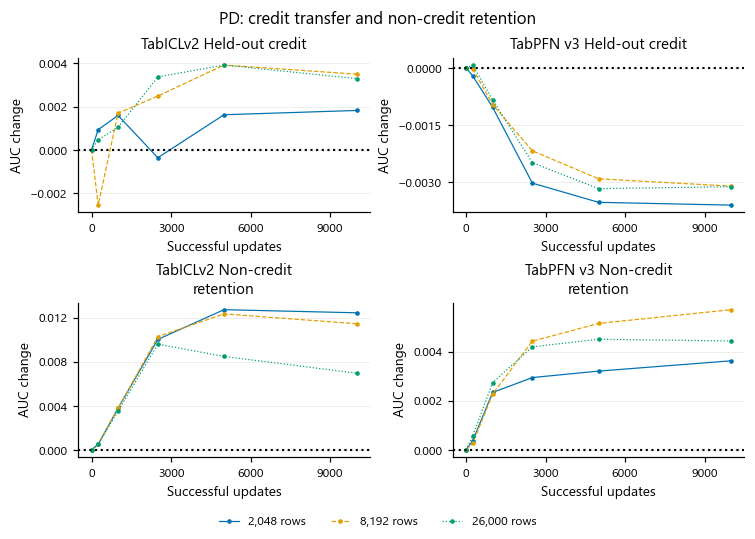

Fixed-context monitoring effects relative to update zero, with equal weight per table. All arms must be observed for the same table; non-credit tables additionally require all four partitions. The baseline table cohort is held fixed across milestones. These monitors are distinct from the final five-fold benchmark.

In [4]:
cp.show(sink, ss.plot_monitors(arms))
report.add('3. Credit and non-credit learning curves', 'Each curve uses fixed table support and matched arms. Non-credit tables require all four training partitions. No final benchmark scores enter these curves.')

## 4. Exposure and computational cost

In [5]:
report.table('Per-trial exposure and resource costs', ss.cost_table(arms))
report.add('4. Exposure and computational cost', 'Updates do not equate row exposure, unique rows or GPU time. Repeated row exposures are not unique-data counts. No compute-normalized causal claim is made.')

,trial_name,base,partition,status,total_optimizer_steps,rows_seen,gpu_hours,sec_per_step,peak_gpu_gb,training_seconds,compute_seconds,arm
0,cpt_episode_rows2048_v1_s00_pd_tabpfn-v3-class...,TabPFN v3,0,OK,10000,20480000,0.438779,0.157960,11.064,1506.769205,1424.411535,"2,048 rows"
1,cpt_episode_rows2048_v1_s00_pd_tabicl-classifi...,TabICLv2,0,OK,10000,20480000,0.300510,0.108184,2.788,1032.859484,968.912538,"2,048 rows"
2,cpt_episode_rows2048_v1_s01_pd_tabpfn-v3-class...,TabPFN v3,1,OK,10000,20480000,0.438452,0.157843,11.064,1509.331604,1418.516946,"2,048 rows"
3,cpt_episode_rows2048_v1_s01_pd_tabicl-classifi...,TabICLv2,1,OK,10000,20480000,0.316309,0.113871,2.788,1091.978493,1011.191201,"2,048 rows"
4,cpt_episode_rows2048_v1_s02_pd_tabpfn-v3-class...,TabPFN v3,2,OK,10000,20480000,0.443828,0.159778,11.064,1528.961603,1451.997773,"2,048 rows"
5,cpt_episode_rows2048_v1_s02_pd_tabicl-classifi...,TabICLv2,2,OK,10000,20480000,0.301245,0.108448,2.788,1037.282291,970.475350,"2,048 rows"
6,cpt_episode_rows2048_v1_s03_pd_tabpfn-v3-class...,TabPFN v3,3,OK,10000,20480000,0.426835,0.153661,11.064,1461.440643,1396.464772,"2,048 rows"
7,cpt_episode_rows2048_v1_s03_pd_tabicl-classifi...,TabICLv2,3,OK,10000,20480000,0.289941,0.104379,2.788,990.704304,929.684087,"2,048 rows"
8,cpt_corpus_v1_s00_pd_tabpfn-v3-classifier-v3_d...,TabPFN v3,0,OK,10000,81920000,0.713752,0.256951,39.288,2497.165584,2361.721721,"8,192 rows"
9,cpt_corpus_v1_s00_pd_tabicl-classifier-v2-2026...,TabICLv2,0,OK,10000,81920000,0.703401,0.253224,8.969,2483.456363,2374.875873,"8,192 rows"


## Additional TabPFN v2 and v2.6 coverage

The exploratory extension preserves the original dataset partitions and reports its evidence separately.

In [6]:
from src.visualize import legacy_extensions
legacy_extensions.render(report, sink, 7, 'training')

## Complete text summary

In [7]:
print(report.summary(sink))

Experiment 9: training episode size — training

0. Evidence and scope
DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.
Compare 2,048, 8,192 and 26,000 total training rows on one fixed large-table pool. The 8,192-row control is reused explicitly from experiment 8. Context and query size both increase; update budgets, not compute or row exposures, are matched.

1. Coverage and the fixed evaluation population
Missing records are unavailable evidence. PENDING is not a live scheduler state. The four original dataset partitions and five row-level evaluation folds remain fixed. Shared controls count once.

Table: Planned and recorded evidence
CSV (first column: row index)
row,arm,source_experiment,source_run,planned,completed,other_outcomes,pending,trajectory_records,benchmark_fold_records
0,"2,048 rows",experiment7,cpt_episode_rows2048_v1,8,8,0,0,48,1155
1,"8,192 rows",experiment6,c